# Bures Mean-Field Convergence: Quadratic and Smooth-Lasso Losses

This notebook integrates the covariance-only Bures gradient flow for a regularized matrix factorization objective. The optimization variable is represented through the lower-left covariance block $S_{vu}=S_{uv}^\top$, while the smooth L1 regularizer acts on the product $S_{vu}$ rather than separately on its factors. The user-facing teacher `oracle_uv` has shape `(d_u, d_v)`, so the data term is centered at `oracle_uv.T`.

The predictor objective is

$$
\ell(S_{vu})
= \frac12\|S_{vu}-S_{\rm teach}\|_F^2
+ \lambda\sum_{i,j}\left(\sqrt{(S_{vu})_{ij}^2+\delta^2}-\delta\right),
\qquad S_{\rm teach}=\texttt{oracle\_uv.T}.
$$

The Bures force uses

$$
E=\nabla\ell(S_{vu})
= S_{vu}-S_{\rm teach}
+ \lambda\frac{S_{vu}}{\sqrt{S_{vu}\odot S_{vu}+\delta^2}},
$$

where the fraction is taken entrywise. With $C_z=I$, the quadratic data term supplies the global PL constant

$$
\kappa=1,
\qquad
L=1+\frac{\lambda}{\delta}.
$$

We begin with $\lambda=0$, which is exactly the whitened quadratic objective, and then turn on the product-level regularizer in a direct comparison. For $\lambda>0$, the minimizer is a smooth shrinkage of the teacher. The notebook therefore computes the minimizer $S_{\rm reg}$ entrywise, stores `loss` as the gap $\ell(S_{vu})-\ell(S_{\rm reg})$, and stores `predictor_error_fro` as $\|S_{vu}-S_{\rm reg}\|_F$.

The covariance is partitioned as

$$
\Sigma =
\begin{pmatrix}
\Sigma^u & \Sigma^{uv} \\
\Sigma^{vu} & \Sigma^v
\end{pmatrix},
\qquad
G =
\begin{pmatrix}
0 & E^\top \\
E & 0
\end{pmatrix}.
$$

We solve

$$
\dot\Sigma = -(G\Sigma + \Sigma G)
$$

with SciPy's explicit Runge-Kutta solvers, and estimate tail exponential rates from the loss gap and distance to the regularized minimizer. The sharp hyperbolic guide is $e^{-4\alpha\kappa t}=e^{-4\alpha t}$.


In [1]:
from __future__ import annotations

import os
from dataclasses import dataclass
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np
from typing import Optional
from numpy.typing import NDArray
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

Array = NDArray[np.float64]

LASSO_LAMBDA = 0.0
LASSO_DELTA = 0.01
REGULARIZED_LAMBDA = 0.1
PL_KAPPA = 1.0
SMOOTHNESS_L = 1.0 + LASSO_LAMBDA / LASSO_DELTA

plt.rcParams.update({
    "font.size": 6,
    "font.family": "serif",
    "axes.titlesize": 8,
    "axes.labelsize": 6,
    "legend.fontsize": 6,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "pgf.preamble": "\n".join([
        r"\usepackage{amsfonts}",
        r"\usepackage{amssymb}",
    ]),
})

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "code" / "figures").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the repository")

FIG_DIR = ROOT / "code" / "figures"
RESULTS_DIR = ROOT / "code" / "notebooks" / "research" / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_SIZE = (4.0, 3.0)
SINGLE_PANEL_SIZE = (4.0, 2.35)
TWO_PANEL_SIZE = (6.0, 2.35)
THREE_PANEL_SIZE = (6.0, 2.25)
GRID_STYLE = {"which": "both", "color": "#E8E8E8", "linewidth": 0.8}
COLORS = ["#2458A6", "#D1495B", "#00876C", "#7A3E9D", "#E08D2D", "#2B8CBE"]

def save_figure(fig, output, *, dpi=200, formats=("pdf", "pgf", "png")):
    if output is None:
        return

    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    for suffix in formats:
        fig.savefig(output.with_suffix(f".{suffix}"), dpi=dpi)

## Core Bures Flow Utilities

In [2]:
@dataclass(frozen=True)
class FlowConfig:
    d_u: int
    d_v: int
    oracle_uv: Array
    sigma0: Array
    lasso_lambda: float = LASSO_LAMBDA
    lasso_delta: float = LASSO_DELTA
    t_final: float = 80.0
    n_eval: int = 801
    rtol: float = 1e-9
    atol: float = 1e-11
    method: str = "RK45"


@dataclass(frozen=True)
class FlowResult:
    t: Array
    sigma: Array
    loss: Array
    predictor_error_fro: Array
    min_eig_sigma: Array
    invariant_drift_fro: Array
    loss_rate: float
    error_rate: float
    success: bool
    message: str
    nfev: int


@dataclass(frozen=True)
class ParticleConfig:
    d_u: int
    d_v: int
    oracle_uv: Array
    n_particles: int
    alpha: float
    lasso_lambda: float = LASSO_LAMBDA
    lasso_delta: float = LASSO_DELTA
    rng_seed: int = 0
    u0: Array | None = None
    v0: Array | None = None
    t_final: float = 80.0
    n_eval: int = 801
    rtol: float = 1e-8
    atol: float = 1e-10
    method: str = "RK45"


@dataclass(frozen=True)
class ParticleResult:
    t: Array
    sigma: Array
    loss: Array
    predictor_error_fro: Array
    min_eig_sigma: Array
    initial_u: Array
    initial_v: Array
    final_u: Array
    final_v: Array
    n_particles: int
    alpha: float
    loss_rate: float
    error_rate: float
    success: bool
    message: str
    nfev: int


def symmetrize(a: Array) -> Array:
    return 0.5 * (a + a.T)


def identity_covariance(d_u: int, d_v: int, scale: float = 1.0) -> Array:
    if scale <= 0:
        raise ValueError("identity covariance scale must be positive")
    return scale * np.eye(d_u + d_v)


def random_oracle_uv(d_u: int, d_v: int, rng: np.random.Generator, scale: float = 1.0) -> Array:
    return scale * rng.standard_normal((d_u, d_v)) / np.sqrt(max(d_u, 1))


def smooth_l1_value(x: Array, delta: float = LASSO_DELTA) -> Array:
    if delta <= 0:
        raise ValueError("lasso_delta must be positive")
    return np.sqrt(x * x + delta * delta) - delta


def smooth_l1_grad(x: Array, delta: float = LASSO_DELTA) -> Array:
    if delta <= 0:
        raise ValueError("lasso_delta must be positive")
    return x / np.sqrt(x * x + delta * delta)


def predictor_objective_and_gradient_vu(
    s_vu: Array,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[float, Array]:
    if lasso_lambda < 0:
        raise ValueError("lasso_lambda must be nonnegative")
    if lasso_delta <= 0:
        raise ValueError("lasso_delta must be positive")
    teacher_vu = oracle_uv.T
    if s_vu.shape != teacher_vu.shape:
        raise ValueError(f"s_vu has shape {s_vu.shape}, expected {teacher_vu.shape}")
    residual_vu = s_vu - teacher_vu
    quadratic = 0.5 * float(np.sum(residual_vu * residual_vu))
    regularizer = lasso_lambda * float(np.sum(smooth_l1_value(s_vu, lasso_delta)))
    gradient = residual_vu + lasso_lambda * smooth_l1_grad(s_vu, lasso_delta)
    return quadratic + regularizer, gradient


def regularized_minimizer_vu(
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> Array:
    if lasso_lambda < 0:
        raise ValueError("lasso_lambda must be nonnegative")
    if lasso_delta <= 0:
        raise ValueError("lasso_delta must be positive")
    teacher_vu = oracle_uv.T
    if lasso_lambda == 0:
        return np.array(teacher_vu, dtype=float, copy=True)

    minimizer = np.empty_like(teacher_vu, dtype=float)
    for index, b in np.ndenumerate(teacher_vu):
        if b == 0:
            minimizer[index] = 0.0
            continue

        def stationarity(x: float) -> float:
            return x - b + lasso_lambda * x / np.sqrt(x * x + lasso_delta * lasso_delta)

        lo, hi = (0.0, float(b)) if b > 0 else (float(b), 0.0)
        minimizer[index] = brentq(stationarity, lo, hi, xtol=1e-13, rtol=1e-13)
    return minimizer


def objective_minimum(
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[Array, float]:
    s_reg = regularized_minimizer_vu(oracle_uv, lasso_lambda, lasso_delta)
    ell_star, _ = predictor_objective_and_gradient_vu(s_reg, oracle_uv, lasso_lambda, lasso_delta)
    return s_reg, ell_star


def initialize_particles_from_isotropic_covariance(
    d_u: int,
    d_v: int,
    n_particles: int,
    alpha: float,
    rng: np.random.Generator,
) -> tuple[Array, Array]:
    if n_particles <= 0:
        raise ValueError("n_particles must be positive")
    if alpha < 0:
        raise ValueError("alpha must be nonnegative")
    scale = np.sqrt(alpha)
    u = scale * rng.standard_normal((d_u, n_particles))
    v = scale * rng.standard_normal((d_v, n_particles))
    return u, v


def empirical_predictor_vu(u: Array, v: Array) -> Array:
    if u.ndim != 2 or v.ndim != 2:
        raise ValueError("u and v must be matrices with particles in columns")
    if u.shape[1] != v.shape[1]:
        raise ValueError("u and v must have the same number of particles")
    return v @ u.T / u.shape[1]


def empirical_covariance_from_particles(u: Array, v: Array) -> Array:
    if u.ndim != 2 or v.ndim != 2:
        raise ValueError("u and v must be matrices with particles in columns")
    if u.shape[1] != v.shape[1]:
        raise ValueError("u and v must have the same number of particles")
    particles = np.vstack([u, v])
    return symmetrize(particles @ particles.T / u.shape[1])


def particle_loss_and_field(
    u: Array,
    v: Array,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[float, Array]:
    d_u, _n_particles = u.shape
    d_v = v.shape[0]
    if oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {oracle_uv.shape}, expected {(d_u, d_v)}")
    predictor_vu = empirical_predictor_vu(u, v)
    return predictor_objective_and_gradient_vu(predictor_vu, oracle_uv, lasso_lambda, lasso_delta)


def split_blocks(sigma: Array, d_u: int, d_v: int) -> tuple[Array, Array, Array, Array]:
    m = d_u + d_v
    if sigma.shape != (m, m):
        raise ValueError(f"sigma has shape {sigma.shape}, expected {(m, m)}")
    s_u = sigma[:d_u, :d_u]
    s_uv = sigma[:d_u, d_u:]
    s_vu = sigma[d_u:, :d_u]
    s_v = sigma[d_u:, d_u:]
    return s_u, s_uv, s_vu, s_v


def predictor_loss_and_gradient(
    sigma: Array,
    d_u: int,
    d_v: int,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[float, Array]:
    if oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {oracle_uv.shape}, expected {(d_u, d_v)}")
    _, _, s_vu, _ = split_blocks(sigma, d_u, d_v)
    return predictor_objective_and_gradient_vu(s_vu, oracle_uv, lasso_lambda, lasso_delta)


def bures_rhs_matrix(
    sigma: Array,
    d_u: int,
    d_v: int,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> Array:
    _, gradient_vu = predictor_loss_and_gradient(sigma, d_u, d_v, oracle_uv, lasso_lambda, lasso_delta)
    m = d_u + d_v
    g = np.zeros((m, m))
    g[:d_u, d_u:] = gradient_vu.T
    g[d_u:, :d_u] = gradient_vu
    return symmetrize(-(g @ sigma + sigma @ g))


def bures_rhs_flat(
    _t: float,
    y: Array,
    d_u: int,
    d_v: int,
    oracle_uv: Array,
    lasso_lambda: float,
    lasso_delta: float,
) -> Array:
    m = d_u + d_v
    sigma = symmetrize(y.reshape(m, m))
    return bures_rhs_matrix(sigma, d_u, d_v, oracle_uv, lasso_lambda, lasso_delta).reshape(-1)


def signature_matrix(d_u: int, d_v: int) -> Array:
    return np.diag(np.concatenate([np.ones(d_u), -np.ones(d_v)]))


def predictor_block_norms(result: FlowResult, d_u: int, d_v: int) -> Array:
    return np.array([
        np.linalg.norm(split_blocks(sigma, d_u, d_v)[2], ord="fro")
        for sigma in result.sigma
    ])


def sublevel_radius_bound(result: FlowResult, d_u: int, d_v: int) -> float:
    # Unit strong convexity bounds both distances through a minimizer.
    initial_norm = np.linalg.norm(split_blocks(result.sigma[0], d_u, d_v)[2], ord="fro")
    return float(initial_norm + 2.0 * np.sqrt(2.0 * result.loss[0]))


def coarse_ellipticity_constant(alpha: float, m: int, M: float) -> float:
    denominator = np.sqrt(m * alpha**2 + 2.0 * M**2) + M
    return float(alpha * (alpha / denominator) ** (m - 1))


def estimate_exponential_rate(
    t: Array,
    values: Array,
    tail_fraction: float = 0.5,
    floor: float = 1e-14,
    relative_floor: float = 1e-8,
) -> float:
    if not (0 < tail_fraction <= 1):
        raise ValueError("tail_fraction must be in (0, 1]")
    values = np.asarray(values)
    finite_positive = values[np.isfinite(values) & (values > 0)]
    if len(finite_positive) < 3:
        return float("nan")
    threshold = max(floor, float(finite_positive[0]) * relative_floor)
    mask = np.isfinite(values) & (values > threshold)
    if np.count_nonzero(mask) < 3:
        return float("nan")
    t_fit = t[mask]
    v_fit = values[mask]
    start = max(0, int(np.floor((1.0 - tail_fraction) * len(t_fit))))
    if len(t_fit) - start < 3:
        start = max(0, len(t_fit) - 3)
    slope, _intercept = np.polyfit(t_fit[start:], np.log(v_fit[start:]), deg=1)
    return float(-slope)


In [3]:
def solve_bures_flow(config: FlowConfig) -> FlowResult:
    d_u, d_v = config.d_u, config.d_v
    m = d_u + d_v
    if config.sigma0.shape != (m, m):
        raise ValueError(f"sigma0 has shape {config.sigma0.shape}, expected {(m, m)}")
    if config.oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {config.oracle_uv.shape}, expected {(d_u, d_v)}")
    sigma0 = symmetrize(np.array(config.sigma0, dtype=float, copy=True))
    t_eval = np.linspace(0.0, config.t_final, config.n_eval)
    sol = solve_ivp(
        bures_rhs_flat,
        t_span=(0.0, config.t_final),
        y0=sigma0.reshape(-1),
        args=(d_u, d_v, config.oracle_uv, config.lasso_lambda, config.lasso_delta),
        method=config.method,
        t_eval=t_eval,
        rtol=config.rtol,
        atol=config.atol,
    )

    sigma_path = np.empty((len(sol.t), m, m))
    loss = np.empty(len(sol.t))
    error = np.empty(len(sol.t))
    min_eig = np.empty(len(sol.t))
    invariant_drift = np.empty(len(sol.t))
    j = signature_matrix(d_u, d_v)
    invariant0 = sigma0 @ j @ sigma0
    invariant0_norm = max(1.0, float(np.linalg.norm(invariant0, ord="fro")))
    s_reg, ell_star = objective_minimum(config.oracle_uv, config.lasso_lambda, config.lasso_delta)

    for k, y in enumerate(sol.y.T):
        sigma = symmetrize(y.reshape(m, m))
        sigma_path[k] = sigma
        objective, gradient_vu = predictor_loss_and_gradient(
            sigma,
            d_u,
            d_v,
            config.oracle_uv,
            config.lasso_lambda,
            config.lasso_delta,
        )
        _, _, s_vu, _ = split_blocks(sigma, d_u, d_v)
        loss[k] = max(float(objective - ell_star), 0.0)
        error[k] = float(np.linalg.norm(s_vu - s_reg, ord="fro"))
        min_eig[k] = float(np.linalg.eigvalsh(sigma).min())
        invariant = sigma @ j @ sigma
        invariant_drift[k] = float(np.linalg.norm(invariant - invariant0, ord="fro") / invariant0_norm)

    return FlowResult(
        t=sol.t,
        sigma=sigma_path,
        loss=loss,
        predictor_error_fro=error,
        min_eig_sigma=min_eig,
        invariant_drift_fro=invariant_drift,
        loss_rate=estimate_exponential_rate(sol.t, loss, relative_floor=1e-10),
        error_rate=estimate_exponential_rate(sol.t, error, relative_floor=1e-6),
        success=bool(sol.success),
        message=str(sol.message),
        nfev=int(sol.nfev),
    )


def summarize_result(
    label: str,
    result: FlowResult,
    *,
    alpha: float | None = None,
    d_u: int | None = None,
    d_v: int | None = None,
    kappa: float = 1.0,
) -> dict[str, float | str | bool | int]:
    row = {
        "label": label,
        "initial_loss": result.loss[0],
        "final_loss": result.loss[-1],
        "initial_distance_to_minimizer_fro": result.predictor_error_fro[0],
        "final_distance_to_minimizer_fro": result.predictor_error_fro[-1],
        "tail_loss_rate": result.loss_rate,
        "tail_error_rate": result.error_rate,
        "min_eig_sigma_final": result.min_eig_sigma[-1],
        "max_invariant_drift_fro": float(np.max(result.invariant_drift_fro)),
        "success": result.success,
        "nfev": result.nfev,
    }
    if alpha is not None and d_u is not None and d_v is not None:
        m = d_u + d_v
        M_bound = sublevel_radius_bound(result, d_u, d_v)
        c_coarse = coarse_ellipticity_constant(alpha, m, M_bound)
        row.update({
            "M_bound": M_bound,
            "c_coarse": c_coarse,
            "sharp_loss_rate": 4.0 * alpha * kappa,
            "coarse_loss_rate": 4.0 * c_coarse * kappa,
            "coarse_over_sharp": c_coarse / alpha,
        })
    return row


def resolve_plot_colors(colors, n: int) -> list:
    if n <= 0:
        return []
    if colors is None:
        colors = COLORS
    if isinstance(colors, str):
        try:
            cmap = plt.get_cmap(colors)
        except ValueError:
            if not mcolors.is_color_like(colors):
                raise
            return [colors] * n
        samples = np.linspace(0.15, 0.85, n) if n > 1 else np.array([0.5])
        return [cmap(sample) for sample in samples]
    if callable(colors):
        samples = np.linspace(0.15, 0.85, n) if n > 1 else np.array([0.5])
        return [colors(sample) for sample in samples]
    if mcolors.is_color_like(colors):
        return [colors] * n
    palette = list(colors)
    if not palette:
        raise ValueError("colors must contain at least one color")
    return [palette[idx % len(palette)] for idx in range(n)]


def save_figure(fig, output, *, dpi=200, formats=("pdf", "pgf", "png")):
    if output is None:
        return
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    for suffix in formats:
        fig.savefig(output.with_suffix(f".{suffix}"), dpi=dpi)


def finish_axes(ax, *, title=None, xlabel="time", ylabel=None, yscale="log", legend=None):
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if yscale:
        ax.set_yscale(yscale)
    ax.grid(True, **GRID_STYLE)
    if legend:
        ax.legend(**legend)


def particle_rhs_flat(
    _t: float,
    y: Array,
    d_u: int,
    d_v: int,
    n_particles: int,
    oracle_uv: Array,
    lasso_lambda: float,
    lasso_delta: float,
) -> Array:
    particles = y.reshape(d_u + d_v, n_particles)
    u = particles[:d_u, :]
    v = particles[d_u:, :]
    _, field_vu = particle_loss_and_field(u, v, oracle_uv, lasso_lambda, lasso_delta)
    du = -(field_vu.T @ v)
    dv = -(field_vu @ u)
    return np.vstack([du, dv]).reshape(-1)


def solve_particle_flow(config: ParticleConfig) -> ParticleResult:
    d_u, d_v = config.d_u, config.d_v
    n_particles = config.n_particles
    if config.oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {config.oracle_uv.shape}, expected {(d_u, d_v)}")
    if n_particles <= 0:
        raise ValueError("n_particles must be positive")

    if config.u0 is None or config.v0 is None:
        if config.u0 is not None or config.v0 is not None:
            raise ValueError("u0 and v0 must be provided together")
        rng = np.random.default_rng(config.rng_seed)
        u0, v0 = initialize_particles_from_isotropic_covariance(
            d_u, d_v, n_particles, config.alpha, rng
        )
    else:
        u0 = np.array(config.u0, dtype=float, copy=True)
        v0 = np.array(config.v0, dtype=float, copy=True)
        if u0.shape != (d_u, n_particles):
            raise ValueError(f"u0 has shape {u0.shape}, expected {(d_u, n_particles)}")
        if v0.shape != (d_v, n_particles):
            raise ValueError(f"v0 has shape {v0.shape}, expected {(d_v, n_particles)}")

    y0 = np.vstack([u0, v0]).reshape(-1)
    t_eval = np.linspace(0.0, config.t_final, config.n_eval)
    sol = solve_ivp(
        particle_rhs_flat,
        t_span=(0.0, config.t_final),
        y0=y0,
        args=(d_u, d_v, n_particles, config.oracle_uv, config.lasso_lambda, config.lasso_delta),
        method=config.method,
        t_eval=t_eval,
        rtol=config.rtol,
        atol=config.atol,
    )

    m = d_u + d_v
    sigma_path = np.empty((len(sol.t), m, m))
    loss = np.empty(len(sol.t))
    error = np.empty(len(sol.t))
    min_eig = np.empty(len(sol.t))
    s_reg, ell_star = objective_minimum(config.oracle_uv, config.lasso_lambda, config.lasso_delta)

    for k, y in enumerate(sol.y.T):
        particles = y.reshape(m, n_particles)
        u = particles[:d_u, :]
        v = particles[d_u:, :]
        sigma = empirical_covariance_from_particles(u, v)
        sigma_path[k] = sigma
        objective, field_vu = particle_loss_and_field(
            u,
            v,
            config.oracle_uv,
            config.lasso_lambda,
            config.lasso_delta,
        )
        predictor_vu = empirical_predictor_vu(u, v)
        loss[k] = max(float(objective - ell_star), 0.0)
        error[k] = float(np.linalg.norm(predictor_vu - s_reg, ord="fro"))
        min_eig[k] = float(np.linalg.eigvalsh(sigma).min())

    final_particles = sol.y[:, -1].reshape(m, n_particles)
    return ParticleResult(
        t=sol.t,
        sigma=sigma_path,
        loss=loss,
        predictor_error_fro=error,
        min_eig_sigma=min_eig,
        initial_u=u0,
        initial_v=v0,
        final_u=final_particles[:d_u, :],
        final_v=final_particles[d_u:, :],
        n_particles=n_particles,
        alpha=config.alpha,
        loss_rate=estimate_exponential_rate(sol.t, loss, relative_floor=1e-10),
        error_rate=estimate_exponential_rate(sol.t, error, relative_floor=1e-6),
        success=bool(sol.success),
        message=str(sol.message),
        nfev=int(sol.nfev),
    )


def summarize_particle_result(label: str, result: ParticleResult) -> dict[str, float | str | bool | int]:
    return {
        "label": label,
        "n_particles": result.n_particles,
        "alpha": result.alpha,
        "initial_loss": result.loss[0],
        "final_loss": result.loss[-1],
        "initial_distance_to_minimizer_fro": result.predictor_error_fro[0],
        "final_distance_to_minimizer_fro": result.predictor_error_fro[-1],
        "tail_loss_rate": result.loss_rate,
        "tail_error_rate": result.error_rate,
        "min_eig_sigma_initial": result.min_eig_sigma[0],
        "min_eig_sigma_final": result.min_eig_sigma[-1],
        "success": result.success,
        "nfev": result.nfev,
    }


def particle_result_list(result_or_results) -> list[ParticleResult]:
    if isinstance(result_or_results, ParticleResult):
        return [result_or_results]
    return list(result_or_results)


def finite_width_curve_stats(
    results: list[ParticleResult],
    quantity: str = "loss",
    reference: FlowResult | None = None,
) -> tuple[Array, Array, Array]:
    if not results:
        raise ValueError("results must contain at least one repeat")
    t = results[0].t
    curves = []
    for result in results:
        if not np.allclose(result.t, t):
            raise ValueError("all repeats must use the same time grid")
        if quantity == "loss":
            curve = result.loss
        elif quantity == "covariance_error":
            if reference is None:
                raise ValueError("reference is required for covariance_error")
            curve = np.linalg.norm(result.sigma - reference.sigma, ord="fro", axis=(1, 2))
        else:
            raise ValueError(f"unknown quantity {quantity!r}")
        curves.append(curve)
    curves = np.vstack(curves)
    return t, np.mean(curves, axis=0), np.std(curves, axis=0, ddof=1 if len(results) > 1 else 0)


def plot_mean(
    ax,
    t: Array,
    mean: Array,
    *,
    color,
    label: str,
    linewidth: float = 1.35,
    band_alpha: float = 0.16,
):
    ax.plot(t, mean, color=color, linewidth=linewidth, label=label)


def overplot_individual_curves(ax, curves: list[Array], t: Array, *, color, alpha: float = 0.18):
    for curve in curves:
        ax.plot(t, curve, color=color, linewidth=0.6, alpha=alpha, label="_nolegend_")


def plot_finite_width_comparison(
    mean_field_result: FlowResult,
    particle_results_by_width: dict[int, ParticleResult | list[ParticleResult]],
    *,
    output=None,
    figsize=SINGLE_PANEL_SIZE,
    colors=None,
    show_individual: bool = True,
) -> None:
    legend_height = 0.82
    fig, ax = plt.subplots(
        1,
        1,
        figsize=(figsize[0], figsize[1] + legend_height),
        constrained_layout=False,
    )
    fig.subplots_adjust(left=0.15, right=0.98, top=0.88, bottom=0.25)
    ax.set_yscale("log")
    ax.plot(mean_field_result.t, mean_field_result.loss, color="black", linewidth=1.45, label="mean field")
    plot_colors = resolve_plot_colors(colors, len(particle_results_by_width))
    for idx, (n_particles, result_or_results) in enumerate(particle_results_by_width.items()):
        color = plot_colors[idx]
        results = particle_result_list(result_or_results)
        t, mean, std = finite_width_curve_stats(results, quantity="loss")
        if show_individual:
            overplot_individual_curves(ax, [result.loss for result in results], t, color=color)
        plot_mean(
            ax,
            t,
            mean,
            color=color,
            label=rf"$n={n_particles}$",
        )
    finish_axes(ax, title="Finite-width predictor loss", ylabel=r"$\ell_t-\ell_\star$")
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.04),
        ncol=max(1, len(labels)),
        frameon=True,
    )
    save_figure(fig, output)
    return fig


def plot_finite_width_covariance_error(
    mean_field_result: FlowResult,
    particle_results_by_width: dict[int, ParticleResult | list[ParticleResult]],
    *,
    output=None,
    figsize=SINGLE_PANEL_SIZE,
    colors=None,
    show_individual: bool = True,
) -> None:
    fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=True)
    ax.set_yscale("log")
    plot_colors = resolve_plot_colors(colors, len(particle_results_by_width))
    for idx, (n_particles, result_or_results) in enumerate(particle_results_by_width.items()):
        color = plot_colors[idx]
        results = particle_result_list(result_or_results)
        t, mean, std = finite_width_curve_stats(
            results,
            quantity="covariance_error",
            reference=mean_field_result,
        )
        if show_individual:
            individual_curves = [
                np.linalg.norm(result.sigma - mean_field_result.sigma, ord="fro", axis=(1, 2))
                for result in results
            ]
            overplot_individual_curves(ax, individual_curves, t, color=color)
        plot_mean(
            ax,
            t,
            mean,
            color=color,
            label=rf"$n={n_particles}$",
        )
    finish_axes(ax, title="Covariance sampling error", ylabel=r"$\|\widehat\Sigma_t-\Sigma_t\|_F$")
    ax.legend(frameon=True)
    save_figure(fig, output)
    return fig

def plot_trajectory(
    result: FlowResult,
    title: str = "Bures covariance flow",
    *,
    output=None,
    figsize=TWO_PANEL_SIZE,
) -> None:
    fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=True)
    axes[0].plot(result.t, result.loss, color=COLORS[0], linewidth=1.45)
    axes[1].plot(result.t, np.maximum(result.invariant_drift_fro, 1e-18), color=COLORS[2], linewidth=1.45)
    finish_axes(axes[0], title="Loss gap", ylabel=r"$\ell_t-\ell_\star$")
    finish_axes(axes[1], title=r"$\Sigma J\Sigma$ drift", ylabel="relative drift")
    if title:
        fig.suptitle(title, fontsize=plt.rcParams["axes.titlesize"])
    save_figure(fig, output)
    plt.show()

def plot_scale_sweep(
    results_by_scale: dict[float, FlowResult],
    d_u: int,
    d_v: int,
    kappa: float = 1.0,
    *,
    output=None,
    figsize=SINGLE_PANEL_SIZE,
    colors=None,
    line_colors = None,
    plot_sharp_rate: Optional[list[int]]=None,
    plot_coarse_rate: Optional[list[int]]=None,
    show_legend: bool = True,
) -> None:
    legend_height = 0.82
    fig, ax = plt.subplots(
        1,
        1,
        figsize=(figsize[0], figsize[1] + legend_height),
        constrained_layout=False,
    )
    fig.subplots_adjust(left=0.15, right=0.98, top=0.88, bottom=0.25)
    ax.set_yscale("log")
    plot_colors = resolve_plot_colors(colors, len(results_by_scale))
    line_colors = resolve_plot_colors(line_colors, len(results_by_scale))
    colors_by_alpha: dict[float, str] = {}
    for idx, (alpha, result) in enumerate(results_by_scale.items()):
        color = plot_colors[idx]
        colors_by_alpha[alpha] = color
        ax.plot(result.t, result.loss, color=color, linewidth=1.45, label=rf"$\alpha={alpha:g}$")

    empirical_ylim = ax.get_ylim()
    m = d_u + d_v

    line_colors_by_alpha: dict[float, str] = {}
    for ind, (alpha, result) in enumerate(results_by_scale.items()):
        line_color = line_colors[ind]
        line_colors_by_alpha[alpha] = line_color
        M_bound = sublevel_radius_bound(result, d_u, d_v)
        c_coarse = coarse_ellipticity_constant(alpha, m, M_bound)
        if plot_sharp_rate is None or ind in plot_sharp_rate:
            ax.plot(
                result.t,
                result.loss[0] * np.exp(-4.0 * alpha * kappa * result.t),
                linestyle="--",
                color=line_color,
                linewidth=1.0,
                alpha=0.65,
                label="_nolegend_",
            )
        if plot_coarse_rate is None or ind in plot_coarse_rate:
            ax.plot(
                result.t,
                result.loss[0] * np.exp(-4.0 * c_coarse * kappa * result.t),
                linestyle=":",
                color=line_color,
                linewidth=1.1,
                alpha=0.8,
                label="_nolegend_",
            )

    ax.set_ylim(empirical_ylim)
    finish_axes(ax, title="Loss gap", ylabel=r"$\ell_t-\ell_\star$")
    handles, labels = ax.get_legend_handles_labels()
    if show_legend:
        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.04),
            ncol=max(1, len(results_by_scale)),
            frameon=True,
        )
    save_figure(fig, output)
    return fig

## Initialization Scale Sweep

This first experiment sets $\lambda=0$, recovering the whitened quadratic objective, and compares $\Sigma_0 = \alpha I$ across several values of `alpha`. This exact covariance initialization lies on $\mathcal M_\alpha$. Since $C_z=I$, the predictor loss has PL constant

$$
\kappa=1,
$$

so the sharp hyperbolic loss-gap guide is

$$
\ell_t-\ell_\star \lesssim e^{-4\alpha t}(\ell_0-\ell_\star).
$$

Here $S_{\rm reg}=S_{\rm teach}$, so the plotted distance to the minimizer is the usual predictor error.


In [4]:
d_u, d_v=16, 9
rng = np.random.default_rng(0)
oracle_uv = random_oracle_uv(d_u, d_v, rng)

In [ ]:
init_scales = [0.1, 0.5, 1, 5]
isotropic_results_by_scale: dict[float, FlowResult] = {}

for scale in init_scales:
    sigma0=identity_covariance(d_u, d_v, scale=scale)
    cfg = FlowConfig(
        d_u=d_u,
        d_v=d_v,
        oracle_uv=oracle_uv,
        sigma0=sigma0,
        t_final=40.0,
        n_eval=801,
    )
    isotropic_results_by_scale[scale] = solve_bures_flow(cfg)

scale_summary = [
    summarize_result(
        f"scale={scale:g}",
        res,
        alpha=scale,
        d_u=d_u,
        d_v=d_v,
        kappa=PL_KAPPA,
    )
    for scale, res in isotropic_results_by_scale.items()
]
scale_summary

In [ ]:
fig = plot_scale_sweep(isotropic_results_by_scale, d_u=d_u, d_v=d_v, kappa=PL_KAPPA)
save_figure(fig, FIG_DIR / "bures_mean_field_scale_sweep.pdf")
plt.show()

## Turning On Product-Level Regularization

We now hold the teacher and isotropic initialization fixed and compare the quadratic case $\lambda=0$ with $\lambda>0$. The regularizer is applied directly to the represented product $S_{vu}$:

$$
R_\delta(S_{vu})=\sum_{i,j}\left(\sqrt{(S_{vu})_{ij}^2+\delta^2}-\delta\right).
$$

The positive-$\lambda$ minimizer is a smooth entrywise shrinkage of the teacher. Both objectives retain $\kappa=1$; their smoothness constants are $L=1$ and $L=1+\lambda/\delta$, respectively, while the sharp hyperbolic rate guide remains $4\alpha\kappa=4\alpha$.


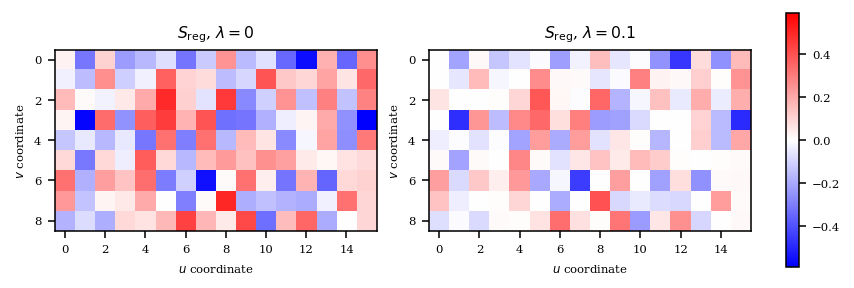

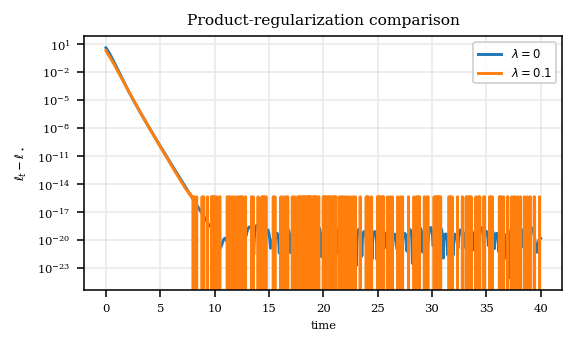

In [7]:
comparison_alpha = 1.0
comparison_lambdas = [LASSO_LAMBDA, REGULARIZED_LAMBDA]
results_by_lambda = {
    lasso_lambda: solve_bures_flow(
        FlowConfig(
            d_u=d_u,
            d_v=d_v,
            oracle_uv=oracle_uv,
            sigma0=identity_covariance(d_u, d_v, scale=comparison_alpha),
            lasso_lambda=lasso_lambda,
            t_final=40.0,
            n_eval=801,
        )
    )
    for lasso_lambda in comparison_lambdas
}

fig, axes = plt.subplots(1, 2, figsize=TWO_PANEL_SIZE, constrained_layout=True)
image_limit = float(np.max(np.abs(oracle_uv)))
for ax, lasso_lambda in zip(axes, comparison_lambdas):
    s_reg = regularized_minimizer_vu(oracle_uv, lasso_lambda, LASSO_DELTA)
    image = ax.imshow(s_reg, cmap="bwr", vmin=-image_limit, vmax=image_limit)
    ax.set_title(rf"$S_{{\rm reg}}$, $\lambda={lasso_lambda:g}$")
    ax.set_xlabel(r"$u$ coordinate")
    ax.set_ylabel(r"$v$ coordinate")
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

fig, ax = plt.subplots(figsize=SINGLE_PANEL_SIZE, constrained_layout=True)
for lasso_lambda, result in results_by_lambda.items():
    ax.plot(result.t, result.loss, label=rf"$\lambda={lasso_lambda:g}$")
finish_axes(ax, title="Product-regularization comparison", ylabel=r"$\ell_t-\ell_\star$", legend={"loc": "best"})
save_figure(fig, FIG_DIR / "bures_mean_field_product_regularization_comparison")
plt.show()

## Compare Coarse and Sharp Rates Using an A Priori Radius

The remark "Coarse ellipticity versus hyperbolic rate" gives the pessimistic nondegeneracy constant

$$
c_\alpha(M)=\alpha\left(\frac{\alpha}{\sqrt{m\alpha^2+2M^2}+M}\right)^{m-1},
$$

where $M$ bounds the entire initial sublevel set. The objectives in this notebook are 1-strongly convex, so $M=\|S_0\|_F+2\sqrt{2(\ell(S_0)-\ell_\star)}$ is an a priori upper bound. For the whitened quadratic baseline with $S_0=0$, it is exactly $2\|S_\star\|_F$, the true sublevel radius. The sharp guide uses $e^{-4\alpha t}$, while the coarse guide uses $e^{-4c_\alpha t}$. No observed trajectory maximum is used as a certified radius.


In [ ]:
init_scales = np.linspace(0.1, 5, 25)
results_by_scale: dict[float, FlowResult] = {}

for scale in init_scales:
    sigma0=identity_covariance(d_u, d_v, scale=scale)
    cfg = FlowConfig(
        d_u=d_u,
        d_v=d_v,
        oracle_uv=oracle_uv,
        sigma0=sigma0,
        t_final=80.0,
        n_eval=801,
    )
    results_by_scale[scale] = solve_bures_flow(cfg)

scale_summary = [
    summarize_result(
        f"scale={scale:g}",
        res,
        alpha=scale,
        d_u=d_u,
        d_v=d_v,
        kappa=PL_KAPPA,
    )
    for scale, res in results_by_scale.items()
]

In [ ]:
plt.scatter([scale_summary[i]['sharp_loss_rate'] for i in range(len(scale_summary))], [scale_summary[i]['coarse_loss_rate'] for i in range(len(scale_summary))])
plt.xlabel("Sharp loss rate")
plt.ylabel("Coarse loss rate")

## Breaking Hyperbolic Isotropy

Here we explore what happens when the initialization is no longer exactly hyperbolically isotropic.  The examples below perturb diagonal entries of the identity-style covariance while keeping the same whitened predictor loss.

For non-isotropic initializations, the sharp hyperbolic-rate formula is no longer justified as a theorem.  The plots are therefore best read as numerical diagnostics rather than guaranteed comparison bounds.


In [10]:
perturb_scales = np.linspace(0., 1.0, 9)
perturbed_results_by_scale: dict[float, FlowResult] = {}

for scale in perturb_scales:
    sigma0=identity_covariance(d_u, d_v, scale=1.0)
    for i in range(1):
        sigma0[i, i] *= scale
        sigma0[i+d_u, i+d_u] *= scale
    cfg = FlowConfig(
        d_u=d_u,
        d_v=d_v,
        oracle_uv=oracle_uv,
        sigma0=sigma0,
        t_final=40.0,
        n_eval=801,
    )
    perturbed_results_by_scale[scale] = solve_bures_flow(cfg)

scale_summary = [
    summarize_result(
        f"scale={scale:g}",
        res,
        alpha=scale,
        d_u=d_u,
        d_v=d_v,
        kappa=PL_KAPPA,
    )
    for scale, res in perturbed_results_by_scale.items()
]
scale_summary;

/tmp/ipykernel_21806/2462606182.py:95: RuntimeWarning: invalid value encountered in scalar divide
  "coarse_over_sharp": c_coarse / alpha,


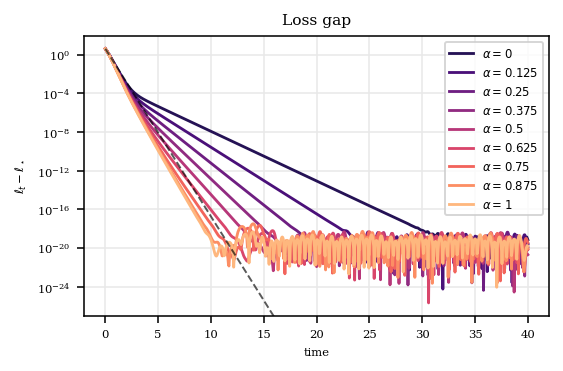

In [11]:
fig=plot_scale_sweep(perturbed_results_by_scale, d_u=d_u, d_v=d_v, kappa=PL_KAPPA, plot_coarse_rate=[], plot_sharp_rate=[len(perturb_scales)-1], colors = "magma", line_colors = ['k', ], show_legend=False)
plt.legend(loc = "upper right")
save_figure(fig, FIG_DIR / "bures_mean_field_perturb_sweep.pdf")
plt.show()

## Finite-Width Particle Gradient Flow

The finite-width model evolves individual particles $x_i=(u_i,v_i)$ rather than the covariance directly. For width $n$, initialize

$$
\nu_0^n=\frac1n\sum_{i=1}^n\delta_{(u_i(0),v_i(0))},
\qquad
\nu_0^n\approx \mathcal N(0,\alpha I),
$$

iid across particles, so the empirical covariance starts near $\alpha I$. The empirical predictor is

$$
\widehat S_{vu}=\frac1n VU^\top,
$$

where `U` and `V` store particles in columns. With the configured predictor gradient $E=\nabla\ell(\widehat S_{vu})$, we use the mean-field particle scaling

$$
\dot u_i=-E^\top v_i,
\qquad
\dot v_i=-E u_i.
$$


In [12]:
finite_alpha = 1.0
finite_widths = [32, 128, 512, 2048]
finite_n_repeats = 5
finite_t_final = 40.0
finite_n_eval = 501

mean_field_config = FlowConfig(
    d_u=d_u,
    d_v=d_v,
    oracle_uv=oracle_uv,
    sigma0=identity_covariance(d_u, d_v, scale=finite_alpha),
    t_final=finite_t_final,
    n_eval=finite_n_eval,
)
mean_field_result = solve_bures_flow(mean_field_config)

particle_results_by_width: dict[int, list[ParticleResult]] = {}
for n_particles in finite_widths:
    repeats = []
    for repeat in range(finite_n_repeats):
        cfg = ParticleConfig(
            d_u=d_u,
            d_v=d_v,
            oracle_uv=oracle_uv,
            n_particles=n_particles,
            alpha=finite_alpha,
            rng_seed=10_000 + 1_000 * n_particles + repeat,
            t_final=finite_t_final,
            n_eval=finite_n_eval,
        )
        repeats.append(solve_particle_flow(cfg))
    particle_results_by_width[n_particles] = repeats

finite_width_summary = []
for n_particles, repeats in particle_results_by_width.items():
    loss_stack = np.vstack([result.loss for result in repeats])
    covariance_error_stack = np.vstack([
        np.linalg.norm(result.sigma - mean_field_result.sigma, ord="fro", axis=(1, 2))
        for result in repeats
    ])
    finite_width_summary.append({
        "n_particles": n_particles,
        "n_repeats": len(repeats),
        "initial_loss_mean": float(np.mean(loss_stack[:, 0])),
        "initial_loss_std": float(np.std(loss_stack[:, 0], ddof=1)),
        "final_loss_mean": float(np.mean(loss_stack[:, -1])),
        "final_loss_std": float(np.std(loss_stack[:, -1], ddof=1)),
        "initial_covariance_error_fro_mean": float(np.mean(covariance_error_stack[:, 0])),
        "initial_covariance_error_fro_std": float(np.std(covariance_error_stack[:, 0], ddof=1)),
        "final_covariance_error_fro_mean": float(np.mean(covariance_error_stack[:, -1])),
        "final_covariance_error_fro_std": float(np.std(covariance_error_stack[:, -1], ddof=1)),
        "all_success": all(result.success for result in repeats),
        "total_nfev": int(sum(result.nfev for result in repeats)),
    })
finite_width_summary


[{'n_particles': 32,
  'n_repeats': 5,
  'initial_loss_mean': 6.386321105262014,
  'initial_loss_std': 0.8881792452181728,
  'final_loss_mean': 3.1516804557774814e-17,
  'final_loss_std': 6.132969132322696e-17,
  'initial_covariance_error_fro_mean': 4.6165812168625315,
  'initial_covariance_error_fro_std': 0.16105084423690885,
  'final_covariance_error_fro_mean': 3.0907030134362836,
  'final_covariance_error_fro_std': 0.2123746859525063,
  'all_success': True,
  'total_nfev': 4228},
 {'n_particles': 128,
  'n_repeats': 5,
  'initial_loss_mean': 4.90674435515147,
  'initial_loss_std': 0.39574176665112343,
  'final_loss_mean': 1.7465387778170655e-17,
  'final_loss_std': 3.4718463094497374e-17,
  'initial_covariance_error_fro_mean': 2.329519409487886,
  'initial_covariance_error_fro_std': 0.07503589630416181,
  'final_covariance_error_fro_mean': 1.5722255247532058,
  'final_covariance_error_fro_std': 0.037403965090497635,
  'all_success': True,
  'total_nfev': 3502},
 {'n_particles': 512,

In [ ]:
fig = plot_finite_width_comparison(
    mean_field_result,
    particle_results_by_width,
)
save_figure(fig, FIG_DIR / "bures_mean_field_finite_width_comparison.pdf")
plt.show()

# Paper triptych: current Figures 2, 4, and 3, in that order.
fig, axes = plt.subplots(1, 3, figsize=(6.5, 1.6875), sharey=True, constrained_layout=False)
fig.subplots_adjust(left=0.075, right=0.995, bottom=0.19, top=0.88, wspace=0.12)

# (a) Isotropic initialization-scale sweep.
ax = axes[0]
isotropic_colors = resolve_plot_colors(COLORS, len(isotropic_results_by_scale))
for idx, (alpha, result) in enumerate(isotropic_results_by_scale.items()):
    color = isotropic_colors[idx]
    ax.plot(result.t, result.loss, color=color, linewidth=1.25, label=rf"$\alpha={alpha:g}$")
    M_bound = sublevel_radius_bound(result, d_u, d_v)
    c_coarse = coarse_ellipticity_constant(alpha, d_u + d_v, M_bound)
    ax.plot(result.t, result.loss[0] * np.exp(-4.0 * alpha * PL_KAPPA * result.t),
            linestyle="--", color=color, linewidth=0.75, alpha=0.65, label="_nolegend_")
    ax.plot(result.t, result.loss[0] * np.exp(-4.0 * c_coarse * PL_KAPPA * result.t),
            linestyle=":", color=color, linewidth=0.8, alpha=0.8, label="_nolegend_")
finish_axes(ax, title="(a) Initialization scale", ylabel=r"$\ell_t-\ell_\star$")
ax.legend(loc="upper right", ncol=2, fontsize=4.6, frameon=True,
          borderpad=0.25, labelspacing=0.2, columnspacing=0.55, handlelength=1.4)

# (b) Symmetry-breaking perturbation sweep.
ax = axes[1]
perturb_colors = resolve_plot_colors("magma", len(perturbed_results_by_scale))
for idx, (scale, result) in enumerate(perturbed_results_by_scale.items()):
    label = rf"$r={scale:g}$" if np.isclose(scale, [0.0, 0.5, 1.0]).any() else "_nolegend_"
    ax.plot(result.t, result.loss, color=perturb_colors[idx], linewidth=1.15, label=label)
last_result = list(perturbed_results_by_scale.values())[-1]
ax.plot(last_result.t, last_result.loss[0] * np.exp(-4.0 * PL_KAPPA * last_result.t),
        linestyle="--", color="black", linewidth=0.8, alpha=0.7, label="_nolegend_")
finish_axes(ax, title="(b) Broken isotropy", ylabel=None)
ax.legend(loc="upper right", ncol=1, fontsize=4.6, frameon=True,
          borderpad=0.25, labelspacing=0.2, handlelength=1.4)

# (c) Mean-field and finite-width particle flows.
ax = axes[2]
ax.plot(mean_field_result.t, mean_field_result.loss, color="black", linewidth=1.3, label="mean field")
finite_colors = resolve_plot_colors(COLORS, len(particle_results_by_width))
for idx, (n_particles, result_or_results) in enumerate(particle_results_by_width.items()):
    color = finite_colors[idx]
    results = particle_result_list(result_or_results)
    t, mean, _ = finite_width_curve_stats(results, quantity="loss")
    overplot_individual_curves(ax, [result.loss for result in results], t, color=color, alpha=0.12)
    plot_mean(ax, t, mean, color=color, label=rf"$n={n_particles}$", linewidth=1.15)
finish_axes(ax, title="(c) Finite width", ylabel=None)
ax.legend(loc="upper right", ncol=1, fontsize=4.4, frameon=True,
          borderpad=0.25, labelspacing=0.18, handlelength=1.3)

# Keep the common vertical range tied to empirical trajectories rather than
# letting the fastest theoretical guide flatten all three panels.
empirical_losses = np.concatenate([
    result.loss[result.loss > 0] for result in isotropic_results_by_scale.values()
])
y_min = 10.0 ** (np.floor(np.log10(empirical_losses.min())) - 1.0)
y_max = 10.0 ** np.ceil(np.log10(empirical_losses.max()))
axes[0].set_ylim(y_min, y_max)

save_figure(fig, FIG_DIR / "bures_convergence_triptych")
plt.show()

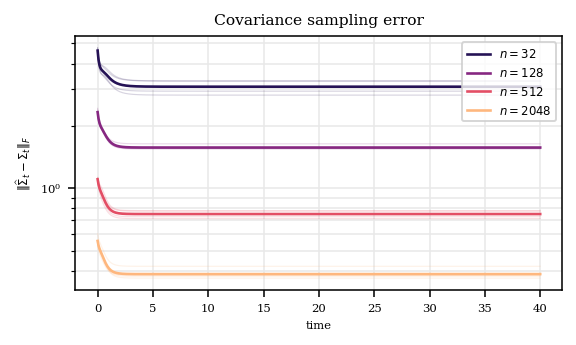

In [14]:
fig = plot_finite_width_covariance_error(
    mean_field_result,
    particle_results_by_width,
    colors="magma",
)
plt.show()


In [15]:
custom_rng = np.random.default_rng(123)
d_u, d_v = 16, 9
oracle_uv = np.eye(d_u, d_v) # random_oracle_uv(d_u, d_v, custom_rng)
# raw = custom_rng.standard_normal((d_u + d_v, d_u + d_v))
# sigma0_custom = raw @ raw.T / (d_u + d_v)
# sigma0_custom += 0.25 * np.eye(d_u + d_v)
sigma0_custom = identity_covariance(d_u, d_v, scale=1)
for i in range(1):
    sigma0_custom[i, i] = 0
    sigma0_custom[i + d_u, i + d_u] = 0

custom_config = FlowConfig(
    d_u=d_u,
    d_v=d_v,
    oracle_uv=oracle_uv,
    sigma0=sigma0_custom,
    t_final=80.0,
    n_eval=801,
)
custom_result = solve_bures_flow(custom_config)
summarize_result("custom", custom_result)

{'label': 'custom',
 'initial_loss': 4.5,
 'final_loss': 0.5,
 'initial_distance_to_minimizer_fro': 3.0,
 'final_distance_to_minimizer_fro': 1.0,
 'tail_loss_rate': -0.0,
 'tail_error_rate': -0.0,
 'min_eig_sigma_final': 0.0,
 'max_invariant_drift_fro': 1.1405159722888376e-09,
 'success': True,
 'nfev': 824}

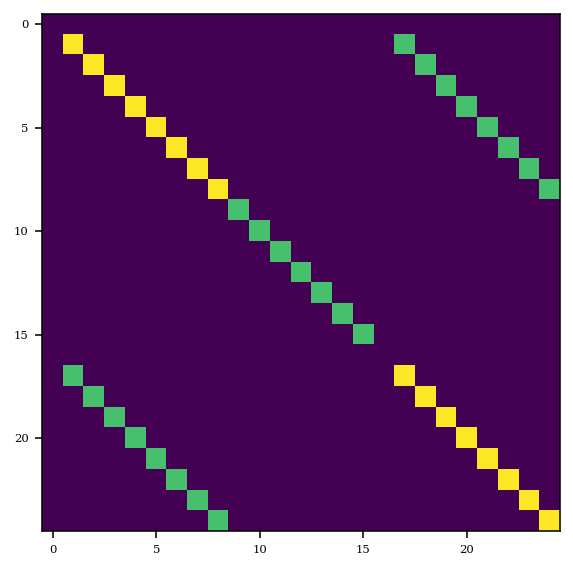

In [16]:
plt.imshow(custom_result.sigma[-1])

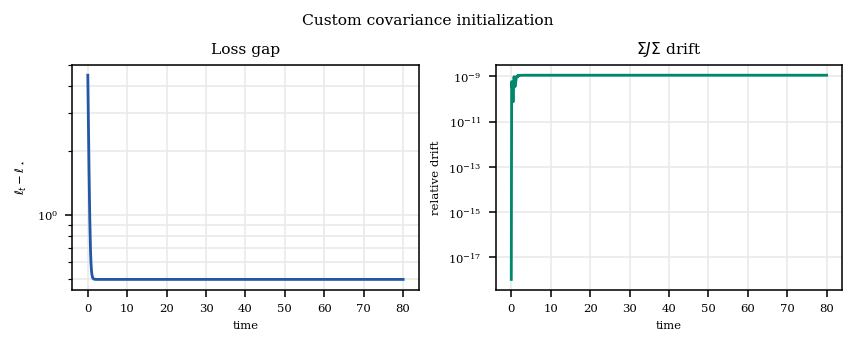

In [17]:
plot_trajectory(custom_result, title="Custom covariance initialization")

## Saving Trajectories

Set `SAVE_OUTPUT = True` to save trajectories and figures. The saved `.npz` file contains `t`, `sigma`, `loss`, `predictor_error_fro`, `min_eig_sigma`, `invariant_drift_fro`, `oracle_uv`, `sigma0`, `lasso_lambda`, `lasso_delta`, and the regularized minimizer `s_reg`.


In [18]:
SAVE_OUTPUT = False

if SAVE_OUTPUT:
    output_dir = RESULTS_DIR / "bures_mean_field_convergence"
    output_dir.mkdir(parents=True, exist_ok=True)

    trajectory_to_save = mean_field_result if "mean_field_result" in globals() else next(iter(results_by_scale.values()))
    s_reg, ell_star = objective_minimum(oracle_uv, LASSO_LAMBDA, LASSO_DELTA)

    np.savez_compressed(
        output_dir / "identity_trajectory.npz",
        t=trajectory_to_save.t,
        sigma=trajectory_to_save.sigma,
        loss=trajectory_to_save.loss,
        predictor_error_fro=trajectory_to_save.predictor_error_fro,
        min_eig_sigma=trajectory_to_save.min_eig_sigma,
        invariant_drift_fro=trajectory_to_save.invariant_drift_fro,
        oracle_uv=oracle_uv,
        sigma0=identity_covariance(d_u, d_v, scale=finite_alpha if "finite_alpha" in globals() else 1.0),
        lasso_lambda=LASSO_LAMBDA,
        lasso_delta=LASSO_DELTA,
        s_reg=s_reg,
        ell_star=ell_star,
    )
    plot_trajectory(
        trajectory_to_save,
        title="Identity covariance initialization",
        output=FIG_DIR / "bures_mean_field_identity_convergence",
    )
    plot_scale_sweep(
        results_by_scale,
        d_u=d_u,
        d_v=d_v,
        kappa=PL_KAPPA,
        output=FIG_DIR / "bures_mean_field_scale_sweep_theory_rates",
    )
    print(output_dir / "identity_trajectory.npz")
